# Task 7 — Time Series Breakdown of Retail Sales

## Project goal

This notebook studies Walmart weekly sales over time, turns them into a monthly retail series, looks for trend and seasonal patterns, compares sales across departments and stores, and builds a simple forecast with exponential smoothing.

**Dataset:** [Walmart Sales Forecasting on Kaggle](https://www.kaggle.com/datasets/anggundwilestari/walmart-sales-forecasting). The local copy contains `train.csv`, `features.csv`, `stores.csv`, and `test.csv`. The source data is historical weekly sales from multiple stores and departments. The Kaggle competition page describes `Weekly_Sales` as department-wide sales for each store and lists the store, department, date, and holiday fields.

**Important scope note:** the data has store and department, but no product or named region fields. For the requested breakdown, `Dept` is used as the closest available product grouping, and `Store`/`Type` are used instead of a region. Results are therefore department/store comparisons, not product/region results. Kaggle lists the dataset under competition rules; the data is not redistributed by this notebook.

## 1. Imports and file paths

Use pandas for loading, joining, grouping, and resampling; matplotlib for charts; and statsmodels' Holt-Winters exponential smoothing for a small, explainable forecast. Update `data_folder` if the CSV files are stored elsewhere.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

data_folder = Path("data/raw/datasets/divyajeetthakur/walmart-sales-prediction/versions/1")
train_path = data_folder / "train.csv"
features_path = data_folder / "features.csv"
stores_path = data_folder / "stores.csv"

print("Train file exists:", train_path.exists())
print("Features file exists:", features_path.exists())
print("Stores file exists:", stores_path.exists())
print("Input folder:", data_folder.resolve())

Train file exists: True
Features file exists: True
Stores file exists: True
Input folder: C:\Users\Fawzy\Documents\Codex\2026-10-22\files-mentioned-by-the-user-data\outputs\Elevvo_Data_Analytics_Portfolio\task-07-retail-time-series\data\raw\datasets\divyajeetthakur\walmart-sales-prediction\versions\1


## 2. Load and inspect the source tables

Load the sales data and supporting tables. Inspect the row counts, columns, date range, missing values, and duplicate sales keys before preparing the time series.

In [2]:
train = pd.read_csv(train_path, parse_dates=["Date"])
features = pd.read_csv(features_path, parse_dates=["Date"])
stores = pd.read_csv(stores_path)

print("train shape:", train.shape)
print("features shape:", features.shape)
print("stores shape:", stores.shape)
print("sales date range:", train["Date"].min().date(), "to", train["Date"].max().date())
print("duplicate Store-Dept-Date rows:", train.duplicated(["Store", "Dept", "Date"]).sum())
display(train.head())
display(stores.head())
display(features.head())

train shape: (421570, 5)
features shape: (8190, 12)
stores shape: (45, 3)
sales date range: 2010-02-05 to 2012-10-26


duplicate Store-Dept-Date rows: 0


,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875


,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,2010-02-05,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,2010-02-12,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,2010-02-19,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,2010-02-26,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,2010-03-05,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


## 3. Clean and join the data

Keep one row per store, department, and week. The five markdown columns can be missing because those promotions are not reported for every period, so retain the missing values rather than silently treating them as zero. Join the store attributes and weekly external features to support comparisons later. Then check whether the merge created missing sales or duplicate keys.

In [3]:
sales = train.drop_duplicates(["Store", "Dept", "Date"]).copy()
sales = sales.sort_values(["Date", "Store", "Dept"])

# The training file and features file both contain IsHoliday.
features_for_join = features.drop(columns=["IsHoliday"], errors="ignore")
sales = sales.merge(features_for_join, on=["Store", "Date"], how="left", validate="many_to_one")
sales = sales.merge(stores, on="Store", how="left", validate="many_to_one")

print("Joined rows:", len(sales))
print("Missing Weekly_Sales:", int(sales["Weekly_Sales"].isna().sum()))
print("Missing store type:", int(sales["Type"].isna().sum()))
print("Missing weekly feature rows:", int(sales["Temperature"].isna().sum()))
print("Duplicate keys after joins:", sales.duplicated(["Store", "Dept", "Date"]).sum())
display(sales[["Date", "Store", "Dept", "Weekly_Sales", "IsHoliday", "Type", "Size"]].head())

Joined rows: 421570
Missing Weekly_Sales: 0
Missing store type: 0
Missing weekly feature rows: 0
Duplicate keys after joins: 0


,Date,Store,Dept,Weekly_Sales,IsHoliday,Type,Size
0,2010-02-05,1,1,24924.50,False,A,151315
1,2010-02-05,1,2,50605.27,False,A,151315
2,2010-02-05,1,3,13740.12,False,A,151315
3,2010-02-05,1,4,39954.04,False,A,151315
4,2010-02-05,1,5,32229.38,False,A,151315


## 4. Build the monthly sales time series

The source is weekly, while the task asks for monthly sales. Sum weekly sales by calendar month, using month-end timestamps. A monthly series makes it possible to examine longer-term movement and yearly seasonality. The chart below also includes 3-month and 12-month rolling means to smooth short-term movement.

Number of monthly observations: 32


,Monthly_Sales,Rolling_3M,Rolling_12M
Date,,,
2010-03-31,1.819198e+08,NaN,NaN
2010-04-30,2.314124e+08,NaN,NaN
2010-05-31,1.867109e+08,2.000144e+08,NaN
2010-06-30,1.922462e+08,2.034565e+08,NaN
2010-07-31,2.325801e+08,2.038457e+08,NaN
2010-08-31,1.876401e+08,2.041555e+08,NaN


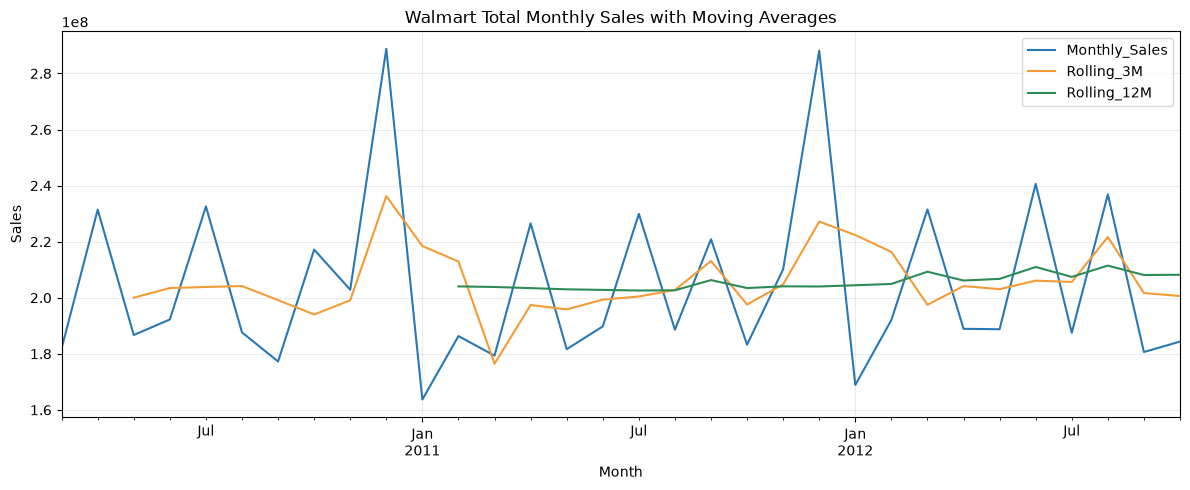

In [4]:
monthly_sales = (
    sales.set_index("Date")["Weekly_Sales"]
    .resample("ME")
    .sum()
    .rename("Monthly_Sales")
    .to_frame()
)

# February 2010 is the first partial calendar month in this dataset.
monthly_sales.loc["2010-02", "Monthly_Sales"] = float("nan")
monthly_sales = monthly_sales.dropna(subset=["Monthly_Sales"])

monthly_sales["Rolling_3M"] = monthly_sales["Monthly_Sales"].rolling(3).mean()
monthly_sales["Rolling_12M"] = monthly_sales["Monthly_Sales"].rolling(12).mean()

print("Number of monthly observations:", len(monthly_sales))
display(monthly_sales.head(6))

ax = monthly_sales[["Monthly_Sales", "Rolling_3M", "Rolling_12M"]].plot(figsize=(12, 5), color=["#2878B5", "#F39C35", "#2E8B57"])
ax.set_title("Walmart Total Monthly Sales with Moving Averages")
ax.set_xlabel("Month")
ax.set_ylabel("Sales")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Examine seasonality by calendar month

Compare average sales for January through December across the years available. The year-by-month table and heatmap show whether the sales pattern tends to repeat within each year. Only a few years are available, so treat the seasonal pattern as descriptive rather than a long-term rule.

Month,1,2,3,4,5,6,7,8,9,10,11,12
Year,,,,,,,,,,,,
2010,NaN,NaN,181919803.0,231412368.0,186710934.0,192246172.0,232580126.0,187640111.0,177267896.0,217161824.0,202853370.0,288760533.0
2011,163703967.0,186331328.0,179356448.0,226526511.0,181648158.0,189773385.0,229911399.0,188599332.0,220847738.0,183261283.0,210162355.0,288078102.0
2012,168894472.0,192063580.0,231509650.0,188920906.0,188766479.0,240610329.0,187509452.0,236850766.0,180645544.0,184361680.0,NaN,NaN


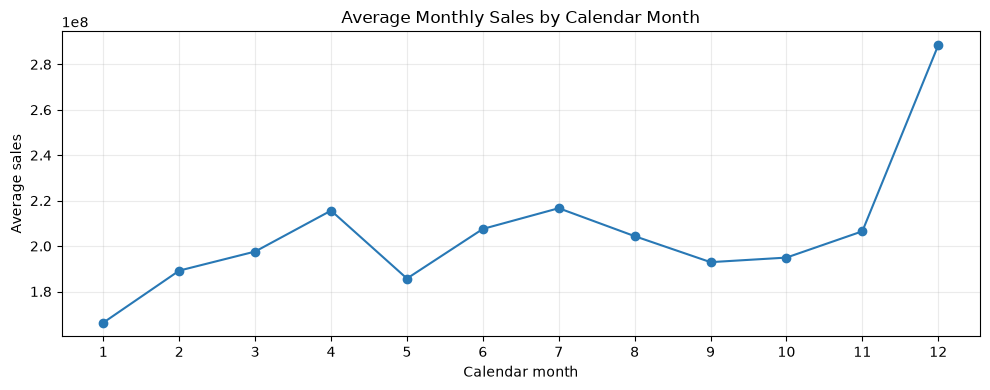

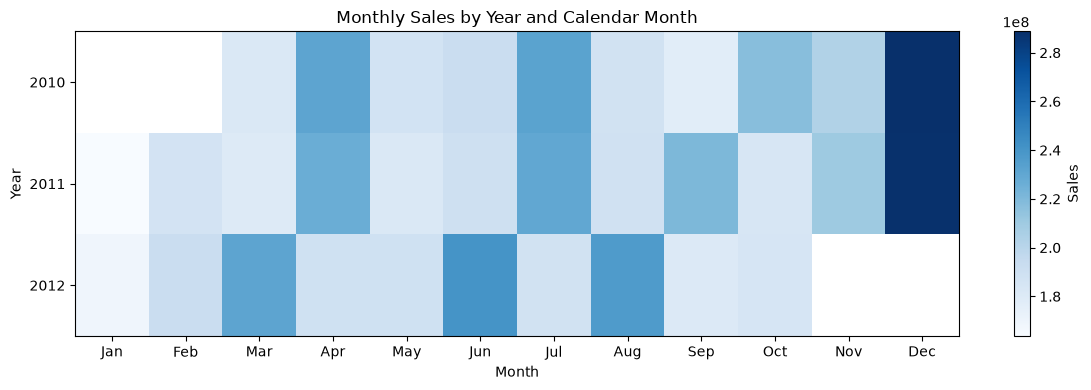

In [5]:
monthly_detail = sales.set_index("Date")["Weekly_Sales"].resample("ME").sum().rename("Sales").to_frame()
monthly_detail.loc["2010-02", "Sales"] = float("nan")
monthly_detail = monthly_detail.dropna(subset=["Sales"])
monthly_detail["Year"] = monthly_detail.index.year
monthly_detail["Month"] = monthly_detail.index.month

seasonal_table = monthly_detail.pivot_table(index="Year", columns="Month", values="Sales", aggfunc="sum")
display(seasonal_table.round(0))

average_by_month = monthly_detail.groupby("Month")["Sales"].mean()
plt.figure(figsize=(10, 4))
plt.plot(average_by_month.index, average_by_month.values, marker="o", color="#2878B5")
plt.xticks(range(1, 13))
plt.title("Average Monthly Sales by Calendar Month")
plt.xlabel("Calendar month")
plt.ylabel("Average sales")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
plt.imshow(seasonal_table, aspect="auto", cmap="Blues")
plt.colorbar(label="Sales")
plt.yticks(range(len(seasonal_table.index)), seasonal_table.index)
plt.xticks(range(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
plt.title("Monthly Sales by Year and Calendar Month")
plt.xlabel("Month")
plt.ylabel("Year")
plt.tight_layout()
plt.show()

## 6. Compare departments and stores over time

There is no product column in these files, so department is the nearest available product-like grouping. Aggregate sales by month and department, then plot the largest departments. For store comparisons, show monthly sales for a small set of the largest stores by total sales; the dataset has store type but no named region.

Dept,92,95,38,72,90
Date,,,,,
2012-03-31,17452679.0,15447693.0,14836579.0,9774677.0,10444260.0
2012-04-30,13954642.0,12708559.0,11714488.0,6755554.0,8365001.0
2012-05-31,13784731.0,13210896.0,11542326.0,6520281.0,8131032.0
2012-06-30,16952188.0,17135419.0,13435245.0,8329348.0,10037229.0
2012-07-31,13736908.0,13715514.0,10907453.0,6549226.0,8079848.0
2012-08-31,17426976.0,16764230.0,13394372.0,8971669.0,10264524.0
2012-09-30,14247589.0,12728892.0,10721470.0,7849142.0,8364475.0
2012-10-31,14776487.0,12315979.0,10711353.0,7561081.0,8611420.0


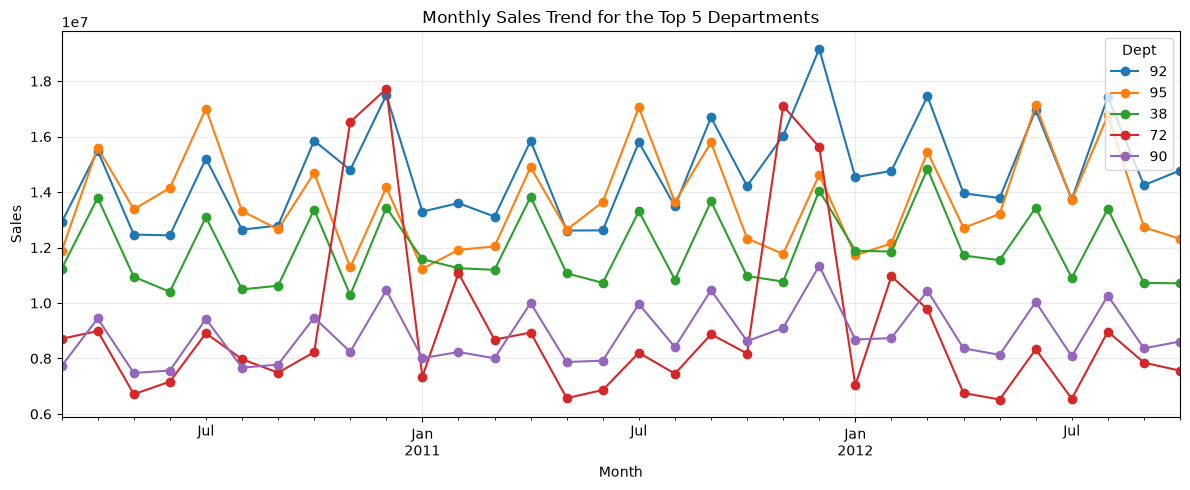

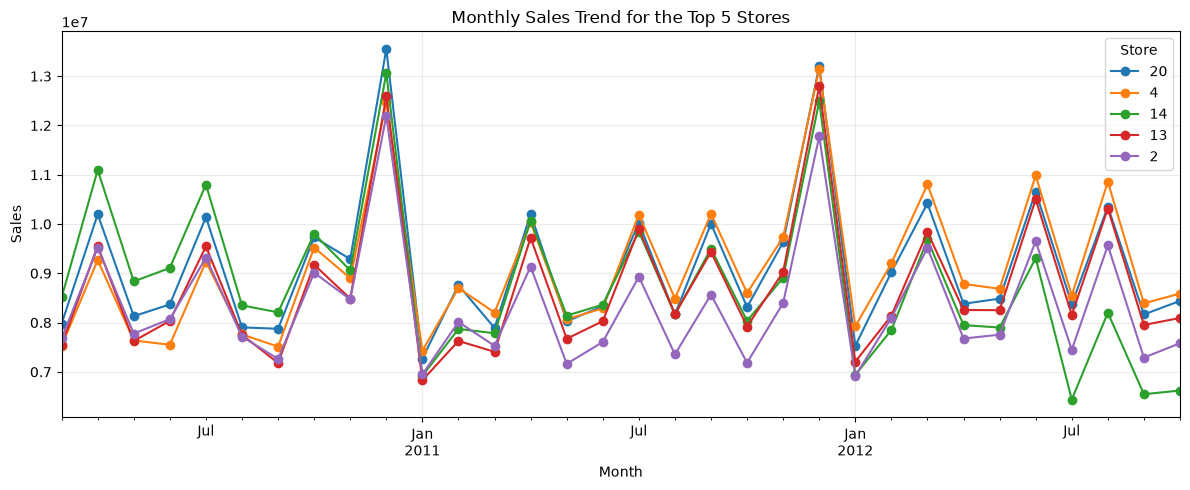

Type,A,B,C
Date,,,
2012-05-31,121924703.0,54897268.0,11944509.0
2012-06-30,154424209.0,71761081.0,14425039.0
2012-07-31,120413737.0,55517377.0,11578338.0
2012-08-31,152567311.0,69869521.0,14413934.0
2012-09-30,116186488.0,52814493.0,11644563.0
2012-10-31,118640083.0,53971520.0,11750077.0


In [6]:
dept_monthly = sales.groupby([pd.Grouper(key="Date", freq="ME"), "Dept"])["Weekly_Sales"].sum().unstack("Dept", fill_value=0)
dept_monthly = dept_monthly.iloc[1:]
top_depts = sales.groupby("Dept")["Weekly_Sales"].sum().nlargest(5).index
display(dept_monthly[top_depts].tail(8).round(0))

ax = dept_monthly[top_depts].plot(figsize=(12, 5), marker="o")
ax.set_title("Monthly Sales Trend for the Top 5 Departments")
ax.set_xlabel("Month")
ax.set_ylabel("Sales")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

store_monthly = sales.groupby([pd.Grouper(key="Date", freq="ME"), "Store"])["Weekly_Sales"].sum().unstack("Store", fill_value=0).iloc[1:]
top_stores = sales.groupby("Store")["Weekly_Sales"].sum().nlargest(5).index
ax = store_monthly[top_stores].plot(figsize=(12, 5), marker="o")
ax.set_title("Monthly Sales Trend for the Top 5 Stores")
ax.set_xlabel("Month")
ax.set_ylabel("Sales")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

store_type_monthly = sales.groupby([pd.Grouper(key="Date", freq="ME"), "Type"])["Weekly_Sales"].sum().unstack("Type", fill_value=0).iloc[1:]
display(store_type_monthly.tail(6).round(0))

## 7. Simple forecast with exponential smoothing

Use Holt-Winters exponential smoothing with additive trend and 12-month seasonality. To evaluate it honestly, hold out the last six observed months, fit using earlier months, and compare the forecast with actual values. Then refit on the full monthly series and produce a six-month illustrative forecast. This small dataset has fewer than three complete years, so seasonal estimates and future forecasts should be treated cautiously.

,Actual,Forecast,Error
2012-05-31,188766479.0,184527053.0,4239427.0
2012-06-30,240610329.0,192466022.0,48144307.0
2012-07-31,187509452.0,232506049.0,-44996597.0
2012-08-31,236850766.0,190828717.0,46022049.0
2012-09-30,180645544.0,180332954.0,312590.0
2012-10-31,184361680.0,220627115.0,-36265434.0


Holdout MAE: 29,996,734
Holdout RMSE: 36,041,294
Holdout MAPE: 14.25%


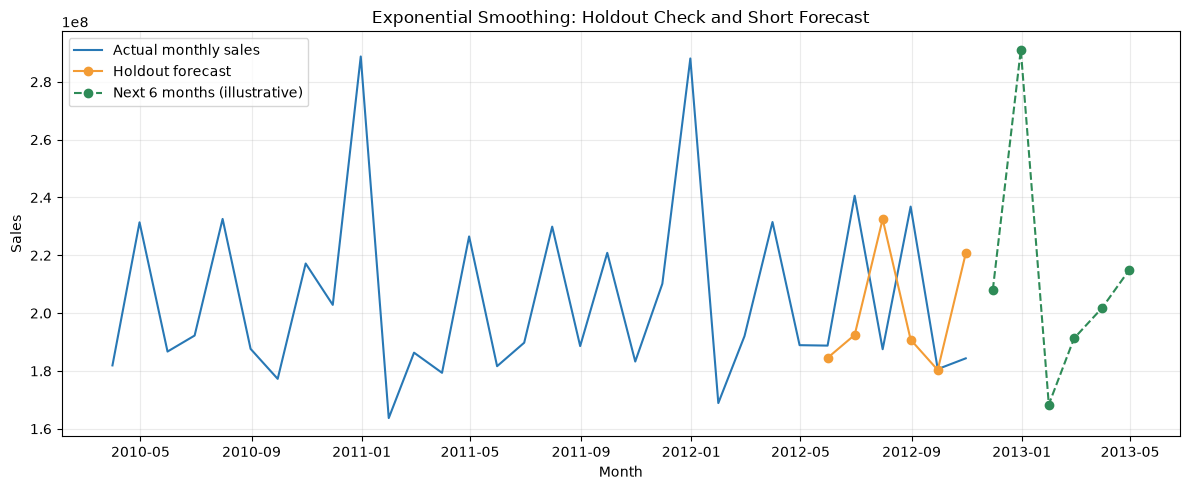

,Forecast
2012-11-30,208084502.0
2012-12-31,291088588.0
2013-01-31,168394587.0
2013-02-28,191290598.0
2013-03-31,201797790.0
2013-04-30,214896421.0


In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

forecast_horizon = 6
holdout_size = 6
train_monthly = monthly_sales["Monthly_Sales"].iloc[:-holdout_size]
test_monthly = monthly_sales["Monthly_Sales"].iloc[-holdout_size:]

backtest_model = ExponentialSmoothing(
    train_monthly,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated",
).fit(optimized=True)
backtest_forecast = backtest_model.forecast(holdout_size)

mae = mean_absolute_error(test_monthly, backtest_forecast)
rmse = np.sqrt(mean_squared_error(test_monthly, backtest_forecast))
mape = (np.abs((test_monthly - backtest_forecast) / test_monthly.replace(0, np.nan))).mean() * 100

backtest_results = pd.DataFrame({"Actual": test_monthly, "Forecast": backtest_forecast})
backtest_results["Error"] = backtest_results["Actual"] - backtest_results["Forecast"]
display(backtest_results.round(0))
print(f"Holdout MAE: {mae:,.0f}")
print(f"Holdout RMSE: {rmse:,.0f}")
print(f"Holdout MAPE: {mape:.2f}%")

full_model = ExponentialSmoothing(
    monthly_sales["Monthly_Sales"],
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated",
).fit(optimized=True)
future_forecast = full_model.forecast(forecast_horizon).rename("Forecast")

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index, monthly_sales["Monthly_Sales"], label="Actual monthly sales", color="#2878B5")
plt.plot(backtest_forecast.index, backtest_forecast, label="Holdout forecast", color="#F39C35", marker="o")
plt.plot(future_forecast.index, future_forecast, label="Next 6 months (illustrative)", color="#2E8B57", marker="o", linestyle="--")
plt.title("Exponential Smoothing: Holdout Check and Short Forecast")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

display(future_forecast.to_frame().round(0))

## 8. Key findings and business interpretation

Summarize what the executed tables and charts show. The code below calculates the strongest month in the history, the largest month-to-month rise and fall, the leading department and store, and the largest holdout forecast error. These are descriptive signals from the available period, not proof of causes.

In [8]:
month_names = monthly_sales["Monthly_Sales"].index.strftime("%B %Y")
monthly_change = monthly_sales["Monthly_Sales"].pct_change() * 100
best_month = monthly_sales["Monthly_Sales"].idxmax()
largest_rise = monthly_change.idxmax()
largest_fall = monthly_change.idxmin()
best_dept = sales.groupby("Dept")["Weekly_Sales"].sum().idxmax()
best_store = sales.groupby("Store")["Weekly_Sales"].sum().idxmax()
largest_error_month = (backtest_results["Actual"] - backtest_results["Forecast"]).abs().idxmax()

print("Highest-sales month:", best_month.strftime("%B %Y"), f"({monthly_sales.loc[best_month, 'Monthly_Sales']:,.0f})")
print("Largest month-to-month rise:", largest_rise.strftime("%B %Y"), f"({monthly_change.loc[largest_rise]:.1f}%)")
print("Largest month-to-month decline:", largest_fall.strftime("%B %Y"), f"({monthly_change.loc[largest_fall]:.1f}%)")
print("Top department by total sales:", int(best_dept))
print("Top store by total sales:", int(best_store))
print("Largest absolute holdout forecast error:", largest_error_month.strftime("%B %Y"), f"({abs(backtest_results.loc[largest_error_month, 'Error']):,.0f})")
print("Forecast error metrics describe only the final six-month holdout.")

Highest-sales month: December 2010 (288,760,533)
Largest month-to-month rise: December 2010 (42.3%)
Largest month-to-month decline: January 2011 (-43.3%)
Top department by total sales: 92
Top store by total sales: 20
Largest absolute holdout forecast error: June 2012 (48,144,307)
Forecast error metrics describe only the final six-month holdout.


## 9. Task coverage and limitations

| Task requirement | Notebook section |
|---|---|
| Analyze monthly retail sales | Section 4 converts weekly sales to monthly totals. |
| Plot trend with moving averages | Section 4 plots monthly sales plus 3-month and 12-month rolling means. |
| Identify seasonal patterns | Section 5 compares calendar months with a table, line chart, and year-month heatmap. |
| Breakdown sales by product/region over time | Section 6 uses department as the closest available product grouping and store/store type instead of region; the source has no product or named region fields. |
| Visualization over time | Sections 4–7 include time-series charts for overall sales, seasonality, departments, stores, and forecast. |
| Bonus: simple forecast / rolling mean / exponential smoothing | Section 7 uses Holt-Winters exponential smoothing, evaluates a 6-month holdout, and forecasts 6 months; Section 4 includes rolling means. |

**Limitations:** the data covers roughly 2 years and 9 months; there are only a few annual cycles for seasonality. A named region and product SKU are not provided, so the breakdown is at store and department levels. The Kaggle `test.csv` contains no target sales values and is not used for evaluation. The forecast is a transparent baseline, not a production demand plan.